In [1]:
import sys
print(sys.executable)

C:\Users\chami\sepsis-early-warning\.venv\Scripts\python.exe


In [2]:
import sys
sys.path.append("..")
from pathlib import Path
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.evaluate import add_onset, bootstrap_metrics, threshold_table, alert_metrics, calibration

THRESHOLD = 0.05  # chosen on validation     
ROOT = Path("..").resolve()
PRED = ROOT / "data" / "predictions"
FIG_DIR = ROOT / "reports" / "figures" / "test"
FIG_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(ROOT / "data" / "sepsis.duckdb"), read_only=True)
cohort = con.execute("""
    SELECT patient_id, septic, onset_iculos, first_iculos, age, gender
    FROM cohort WHERE split = 'test'
""").df()
con.close()

def load(name):
    return add_onset(pd.read_parquet(PRED / f"{name}_test.parquet"), cohort)

main = load("lgbm")
no_ord = load("lgbm-ordering")
print(len(main), main["patient_id"].nunique(), int(cohort["septic"].sum()))
# expect 118406 rows, 3021 patients, 239 septic

118406 3021 239


In [3]:
rows = []
for name, d in [("main", main), ("without ordering", no_ord)]:
    for scope, sub in [("all hours", d), ("pre-onset hours", d[d["pre_onset"]])]:
        m = bootstrap_metrics(sub["y"], sub["p"], sub["patient_id"], n_boot=500)
        rows.append({"model": name, "scope": scope, "random_auprc": round(sub["y"].mean(), 3),
                     **{k: f"{v[0]:.3f} ({v[1]:.3f}–{v[2]:.3f})" for k, v in m.items()}})
pd.DataFrame(rows)

,model,scope,random_auprc,auroc,auprc
0,main,all hours,0.020,0.805 (0.782–0.827),0.091 (0.075–0.112)
1,main,pre-onset hours,0.012,0.793 (0.767–0.816),0.054 (0.044–0.070)
2,without ordering,all hours,0.020,0.794 (0.769–0.817),0.082 (0.068–0.098)
3,without ordering,pre-onset hours,0.012,0.783 (0.758–0.809),0.048 (0.040–0.058)


In [4]:
ops = threshold_table(main, [0.03, THRESHOLD, 0.10])
n_sep = int(cohort["septic"].sum())
ops["septic_caught_early"] = (ops["early_sensitivity"] * n_sep).round().astype(int).astype(str) + f" / {n_sep}"
ops.round(3)

,threshold,early_sensitivity,median_lead_h,alerts_per_100_patient_days,alert_ppv,nonseptic_patients_alerted,septic_caught_early
0,0.03,0.636,8.0,70.456,0.099,0.277,152 / 239
1,0.05,0.485,8.0,39.444,0.132,0.160,116 / 239
2,0.10,0.285,7.5,15.384,0.174,0.060,68 / 239


Mean predicted 0.0165 vs actual positive rate 0.0196 | Brier 0.0186


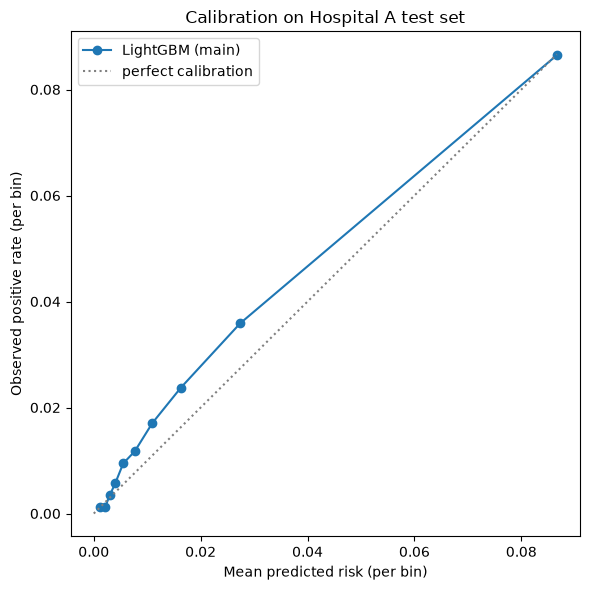

In [5]:
cal, brier = calibration(main["y"], main["p"])
print(f"Mean predicted {main['p'].mean():.4f} vs actual positive rate {main['y'].mean():.4f} | Brier {brier:.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(cal["mean_predicted"], cal["observed_rate"], marker="o", label="LightGBM (main)")
top = max(cal["mean_predicted"].max(), cal["observed_rate"].max())
ax.plot([0, top], [0, top], linestyle=":", color="gray", label="perfect calibration")
ax.set_xlabel("Mean predicted risk (per bin)")
ax.set_ylabel("Observed positive rate (per bin)")
ax.set_title("Calibration on Hospital A test set")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "calibration_test.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
pts = cohort.assign(
    age_group=pd.cut(cohort["age"], [0, 50, 65, 80, 200], right=False,
                     labels=["<50", "50–64", "65–79", "80+"]),
    sex=cohort["gender"].map({0: "female", 1: "male"}),
)
d = main.merge(pts[["patient_id", "age_group", "sex"]], on="patient_id")

def subgroup_rows(col):
    rows = []
    for g, sub in d.groupby(col, observed=True):
        m = bootstrap_metrics(sub["y"], sub["p"], sub["patient_id"], n_boot=200)
        a = alert_metrics(sub, THRESHOLD)
        rows.append({
            "group": f"{col}: {g}",
            "patients": sub["patient_id"].nunique(),
            "septic": int(sub.drop_duplicates("patient_id")["septic"].sum()),
            "auroc (95% CI)": f"{m['auroc'][0]:.3f} ({m['auroc'][1]:.3f}–{m['auroc'][2]:.3f})",
            "early_sensitivity": round(a["early_sensitivity"], 3),
            "nonseptic_alerted": round(a["nonseptic_patients_alerted"], 3),
            "alert_ppv": round(a["alert_ppv"], 3),
        })
    return rows

pd.DataFrame(subgroup_rows("age_group") + subgroup_rows("sex"))

,group,patients,septic,auroc (95% CI),early_sensitivity,nonseptic_alerted,alert_ppv
0,age_group: <50,672,51,0.833 (0.792–0.877),0.549,0.151,0.148
1,age_group: 50–64,831,70,0.788 (0.742–0.835),0.486,0.154,0.138
2,age_group: 65–79,1045,80,0.812 (0.772–0.853),0.500,0.152,0.133
3,age_group: 80+,473,38,0.788 (0.737–0.834),0.368,0.200,0.091
4,sex: female,1294,114,0.784 (0.755–0.814),0.412,0.164,0.129
5,sex: male,1727,125,0.825 (0.794–0.859),0.552,0.157,0.134


In [7]:
sep = cohort[cohort["septic"] == 1].assign(
    history_before_onset=lambda x: x["onset_iculos"] - x["first_iculos"])
sep["history_group"] = np.where(sep["history_before_onset"] <= 24,
                                "onset within 24 h of record start", "onset after 24 h")

rows = []
for g, grp in sep.groupby("history_group"):
    a = alert_metrics(main[main["patient_id"].isin(grp["patient_id"])], THRESHOLD)
    rows.append({"group": g, "septic_patients": len(grp),
                 "early_sensitivity": round(a["early_sensitivity"], 3),
                 "median_lead_h": a["median_lead_h"]})
pd.DataFrame(rows)

,group,septic_patients,early_sensitivity,median_lead_h
0,onset after 24 h,158,0.595,8.0
1,onset within 24 h of record start,81,0.272,7.5


## Findings (Part C: Hospital A test set, evaluated once)
**Discrimination** (95% CIs, 500 patient-level bootstrap resamples; 3,021 patients, 239 septic)
- All hours: AUROC 0.805 (0.782–0.827), AUPRC 0.091 (0.075–0.112); random 0.020
- Pre-onset: AUROC 0.793 (0.767–0.816), AUPRC 0.054 (0.044–0.070); random 0.012
- Without ordering features: AUPRC 0.082 (all hours), 0.048 (pre-onset). Ordering adds +0.009 / +0.006; CIs overlap, same pattern as validation

**Alerting at threshold 0.05** (chosen on validation)
- 116 / 239 septic patients warned early (48.5%), median lead 8 h
- 39.4 alerts per 100 patient-days; alert PPV 13.2% (~8 alerts per true early warning); 16% of non-septic patients alerted
- Alternatives: 0.03 → 64% warned, 70 alerts / 100 pt-days, PPV 9.9%; 0.10 → 28% warned, 15 alerts, PPV 17.4%

**Consistency with validation:** all metrics within noise (validation: AUROC 0.809, early sensitivity 49.6%, PPV 12.3%), so selection on validation did not overfit

**Calibration:** mean predicted 0.0165 vs observed 0.0196, Brier 0.0186; mild underestimation in mid-range risk (e.g. predicted ~2.7% → observed ~3.6%). Not corrected on test; recalibration is part of Day 4

**Subgroups** (threshold 0.05; small groups, wide CIs)
- Age 80+ (38 septic): lower early sensitivity (37%) and more false alarms (20% of non-septic alerted, PPV 9%)
- Female vs male: early sensitivity 41% vs 55%, AUROC 0.784 vs 0.825; false-alarm rates equal. Borderline given ~120 septic patients each
- Both flagged as potential disparities; re-check at Hospital B (919 septic patients)

**Early-stay limitation**
- Onset after first 24 h (158 septic): 60% warned early
- Onset within first 24 h (81 septic, ~1/3 of septic patients): 27% warned early
- Consistent with SHAP: limited history (hours_available24) strongly lowers risk early in the stay